# Week 4 · SQL from Python 🐍 ➜ 🗄️

**10 minutes · run SQL inside a notebook and get the answer as a pandas DataFrame**

| Part | Topic |
|---|---|
| 1 | Get the database file |
| 2 | `sqlite3` (built into Python): connect → query → DataFrame |
| 3 | `duckdb`: SQL directly on a pandas DataFrame |
| 4 | From query to chart |

**Why?** In real projects the data lives in a database, but the analysis, the charts and the
machine-learning models live in Python. SQL **fetches and summarises** the data; pandas **continues** from there.

```
 sakila.db  ──SQL query──▶  pandas DataFrame  ──▶  charts · statistics · ML
```

## Part 1 — Get the database file

We need `sakila.db` (the DVD-rental database from class). The cell looks for it in `data/`
and, if it is not there (for example in Google Colab), downloads it.

In [1]:
from pathlib import Path
import urllib.request

URL = "https://raw.githubusercontent.com/bradleygrant/sakila-sqlite3/main/sakila_master.db"

# Look for the file in the usual places of our class repo
candidates = [Path("data/sakila.db"), Path("../data/sakila.db"), Path("sakila.db")]
DB_PATH = next((p for p in candidates if p.exists()), None)

if DB_PATH is None:                       # not found → download it (≈ 6 MB)
    DB_PATH = Path("sakila.db")
    urllib.request.urlretrieve(URL, DB_PATH)

print("Using:", DB_PATH, "|", round(DB_PATH.stat().st_size / 1e6, 1), "MB")

Using: sakila.db | 5.8 MB


## Part 2 — `sqlite3`: the built-in way

`sqlite3` ships with Python, so there is nothing to install. Three steps:

1. **connect** to the file → a *connection* object
2. **send** an SQL query (a normal Python string)
3. **read** the answer, best as a pandas DataFrame with `pd.read_sql`

In [2]:
import sqlite3
import pandas as pd

con = sqlite3.connect(DB_PATH)   # 1. open the connection
con

The "raw" way returns a list of Python tuples (not very comfortable):

In [3]:
cursor = con.execute("SELECT title, length FROM film LIMIT 3")
cursor.fetchall()

[('ACADEMY DINOSAUR', 86), ('ACE GOLDFINGER', 48), ('ADAPTATION HOLES', 50)]

**The way we use:** `pd.read_sql(query, con)` returns a DataFrame. Triple quotes `"""` let the query span several lines, exactly as in the `.sql` files from class.

In [4]:
query = """
SELECT rating, COUNT(*) AS n_films, ROUND(AVG(length), 1) AS avg_length
FROM film
GROUP BY rating
ORDER BY n_films DESC
"""
df_ratings = pd.read_sql(query, con)
df_ratings

,rating,n_films,avg_length
0,PG-13,223,120.4
1,NC-17,210,113.2
2,R,195,118.7
3,PG,194,112.0
4,G,178,111.1


✅ It is a normal DataFrame: every pandas method from Week 2 works on it.

In [5]:
df_ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rating      5 non-null      str    
 1   n_films     5 non-null      int64  
 2   avg_length  5 non-null      float64
dtypes: float64(1), int64(1), str(1)
memory usage: 252.0 bytes


### Values that change → parameters with `?`

Never glue user values into the SQL string yourself (f-strings). Use `?` placeholders and pass the
values separately: SQLite handles the quotes for you, and it protects against *SQL injection*
(someone typing SQL code into an input field).

In [6]:
min_length = 180
pd.read_sql("SELECT title, length FROM film WHERE length > ? ORDER BY length DESC",
            con, params=(min_length,))

,title,length
0,CHICAGO NORTH,185
1,CONTROL ANTHEM,185
2,DARN FORRESTER,185
3,GANGS PRIDE,185
4,HOME PITY,185
5,MUSCLE BRIGHT,185
6,POND SEATTLE,185
7,SOLDIERS EVOLUTION,185
8,SWEET BROTHERHOOD,185
9,WORST BANGER,185


### A JOIN works exactly the same

Any query from class works here: just paste it into the string.

In [7]:
query = """
SELECT c.first_name || ' ' || c.last_name AS customer,
       ROUND(SUM(p.amount), 2)            AS total_paid
FROM payment p
JOIN customer c ON p.customer_id = c.customer_id
GROUP BY c.customer_id
ORDER BY total_paid DESC
LIMIT 5
"""
pd.read_sql(query, con)

,customer,total_paid
0,KARL SEAL,221.55
1,ELEANOR HUNT,216.54
2,CLARA SHAW,195.58
3,RHONDA KENNEDY,194.61
4,MARION SNYDER,194.61


### Peek at the schema from Python

In [8]:
pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", con)

,name
0,actor
1,address
2,category
3,city
4,country
5,customer
6,film
7,film_actor
8,film_category
9,film_text


## Part 3 — `duckdb`: SQL on DataFrames

**DuckDB** is a small, very fast analytical database that runs inside Python (like SQLite, no server).
Its superpower: it can run SQL **directly on a pandas DataFrame** — just use the variable name as a table name.

Install it once (in the class repo: `uv add duckdb`; in Colab it is usually pre-installed):

In [10]:
# !pip install duckdb      # ← uncomment only if the import below fails
import duckdb
duckdb.__version__

'2.0.0'

In [11]:
films = pd.read_sql("SELECT * FROM film", con)      # a normal DataFrame (1,000 rows)

duckdb.sql("""
    SELECT rental_rate, COUNT(*) AS n_films
    FROM films                        -- ← the Python variable!
    GROUP BY rental_rate
    ORDER BY rental_rate
""").df()                             # .df() turns the result into a DataFrame

,rental_rate,n_films
0,0.99,341
1,2.99,323
2,4.99,336


💡 Handy when you already have a DataFrame (from a CSV, an API, a cleaning step...) and a question is
easier to write in SQL than in pandas. DuckDB also reads files directly:

```python
duckdb.sql("SELECT * FROM 'data/my_file.csv' LIMIT 5").df()
duckdb.sql("SELECT * FROM 'data/*.parquet'").df()      # many files at once
```

### DuckDB can also open the SQLite file itself

DuckDB downloads a small `sqlite` extension the first time (needs internet). After that, you can use the
Sakila tables directly from DuckDB.

In [12]:
try:
    duck = duckdb.connect()
    duck.sql(f"ATTACH '{DB_PATH}' AS sakila (TYPE sqlite)")
    display(duck.sql("SELECT COUNT(*) AS n_rentals FROM sakila.rental").df())
    duck.close()
except Exception as e:
    print("Could not load the sqlite extension (no internet?):", e)

,n_rentals
0,16044


## Part 4 — From query to chart

SQL summarises → pandas plots. Rentals per month:

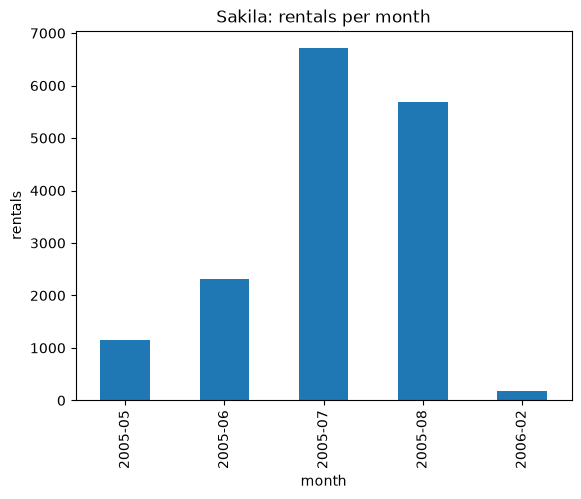

In [13]:
monthly = pd.read_sql("""
    SELECT strftime('%Y-%m', rental_date) AS month, COUNT(*) AS n_rentals
    FROM rental
    GROUP BY month
    ORDER BY month
""", con)

monthly.plot(x="month", y="n_rentals", kind="bar", legend=False,
             title="Sakila: rentals per month", ylabel="rentals");

### Close the connection when you are done

In [14]:
con.close()

---
## 📌 Cheat sheet

| I want to... | Code |
|---|---|
| open a SQLite file | `con = sqlite3.connect("data/sakila.db")` |
| run a query → DataFrame | `pd.read_sql("SELECT ...", con)` |
| pass a value safely | `pd.read_sql("... WHERE x > ?", con, params=(value,))` |
| SQL on a DataFrame | `duckdb.sql("SELECT ... FROM my_df").df()` |
| SQL on a CSV file | `duckdb.sql("SELECT ... FROM 'file.csv'").df()` |
| close | `con.close()` |

### When to use what?
- **SQL** (in the database): filtering, joining and aggregating **big** tables → only the small result comes to Python.
- **pandas**: cleaning, feature engineering, plotting, ML on the result.
- **DuckDB**: SQL on DataFrames and files (CSV, Parquet); very fast on millions of rows.

### Common errors
| Error | Meaning |
|---|---|
| `no such table: films` | wrong table name (Sakila's table is `film`) or wrong file: check `DB_PATH` |
| `unable to open database file` | the path is wrong: print `DB_PATH` |
| `Incorrect number of bindings supplied` | number of `?` ≠ number of values in `params` (and use `(value,)` with a comma) |
| `Cannot operate on a closed database` | you ran `con.close()`: reconnect |
| DuckDB `Table ... does not exist` | the DataFrame variable does not exist (yet) in Python |

---
## 🧪 Try it at home

1. With `pd.read_sql`, get the 10 customers with the most rentals (names + count) and plot them as a horizontal bar chart (`kind="barh"`).
2. Write a function `films_by_rating(rating)` that returns the films of one rating, using a `?` parameter.
3. Load the `payment` table into a DataFrame, then use DuckDB to compute the revenue per `staff_id`.